In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="W9zC1K36ckvKTh6njjt6")
project = rf.workspace("naima-el-menani").project("moroccan-license-plate-detection")
version = project.version(4)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 97.3 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to moroccan-license-plate-detection-4 in yolov8:: 100%|██████████| 5128/5128 [00:00<00:00, 7535.15it/s]


In [2]:
!nvidia-smi

Sun Nov  8 22:33:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
!pip install -q ultralytics roboflow

In [6]:
from roboflow import Roboflow
rf = Roboflow(api_key="W9zC1K36ckvKTh6njjt6")
project = rf.workspace("naima-el-menani").project("moroccan-license-plate-detection")
version = project.version(4)
dataset = version.download("yolov8")
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...
/content/moroccan-license-plate-detection-4


In [7]:
import os
for part in ["train", "valid", "test"]:
    n = len(os.listdir(f"{dataset.location}/{part}/images"))
    print(f"{part:6s} : {n} images")

print(open(f"{dataset.location}/data.yaml").read())

train  : 1897 images
valid  : 407 images
test   : 254 images
names:
- LP
nc: 1
roboflow:
  license: CC BY 4.0
  project: moroccan-license-plate-detection
  url: https://universe.roboflow.com/naima-el-menani/moroccan-license-plate-detection/dataset/4
  version: 4
  workspace: naima-el-menani
test: ../test/images
train: ../train/images
val: ../valid/images



In [8]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    name="plaque",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/moroccan-license-plate-detection-4/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torc

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c175669e190>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [9]:
best = YOLO("runs/detect/plaque/weights/best.pt")
metrics = best.val(split="test")
print("mAP50    :", round(metrics.box.map50, 3))
print("mAP50-95 :", round(metrics.box.map, 3))
print("Précision:", round(metrics.box.mp, 3))
print("Rappel   :", round(metrics.box.mr, 3))

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1693.7±422.4 MB/s, size: 56.1 KB)
val: Scanning /content/moroccan-license-plate-detection-4/test/labels... 254 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 254/254 1.9Kit/s 0.1s
val: New cache created: /content/moroccan-license-plate-detection-4/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.4it/s 3.6s
                   all        254        255      0.968      0.976      0.979      0.715
Speed: 2.1ms preprocess, 4.7ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/detect/val
mAP50    : 0.979
mAP50-95 : 0.715
Précision: 0.968
Rappel   : 0.976



0: 640x640 1 LP, 6.3ms
1: 640x640 1 LP, 6.3ms
2: 640x640 1 LP, 6.3ms
Speed: 0.9ms preprocess, 6.3ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/demo


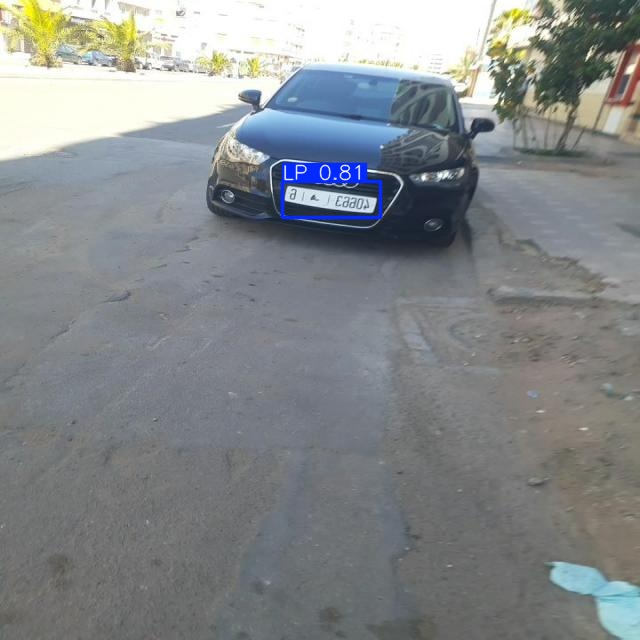

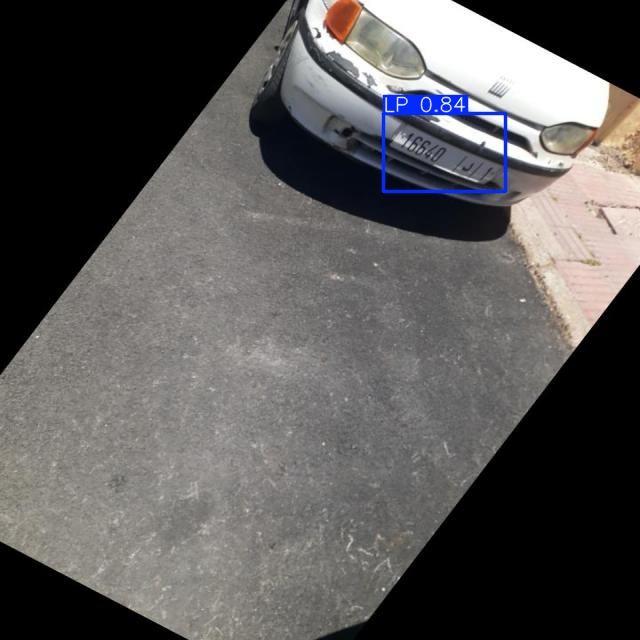

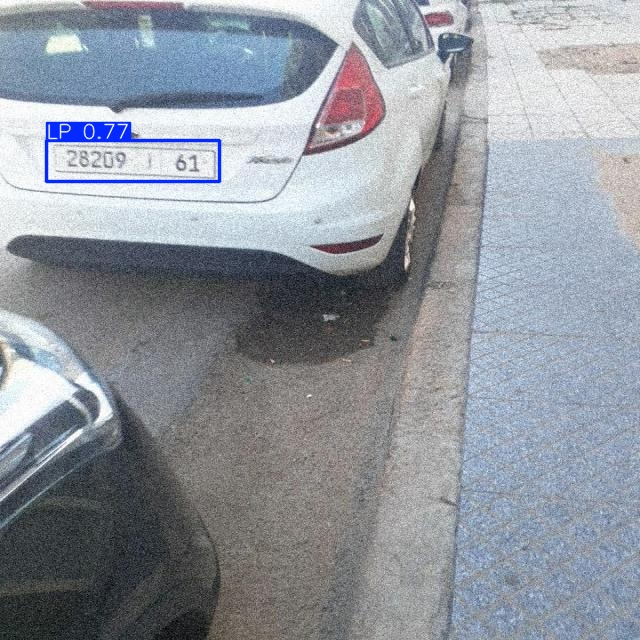

In [10]:
import glob
from IPython.display import Image, display
imgs = glob.glob(f"{dataset.location}/test/images/*")[:3]
best.predict(imgs, save=True, name="demo", conf=0.25)
for f in glob.glob("runs/detect/demo*/*.jpg")[:3]:
    display(Image(f, width=500))

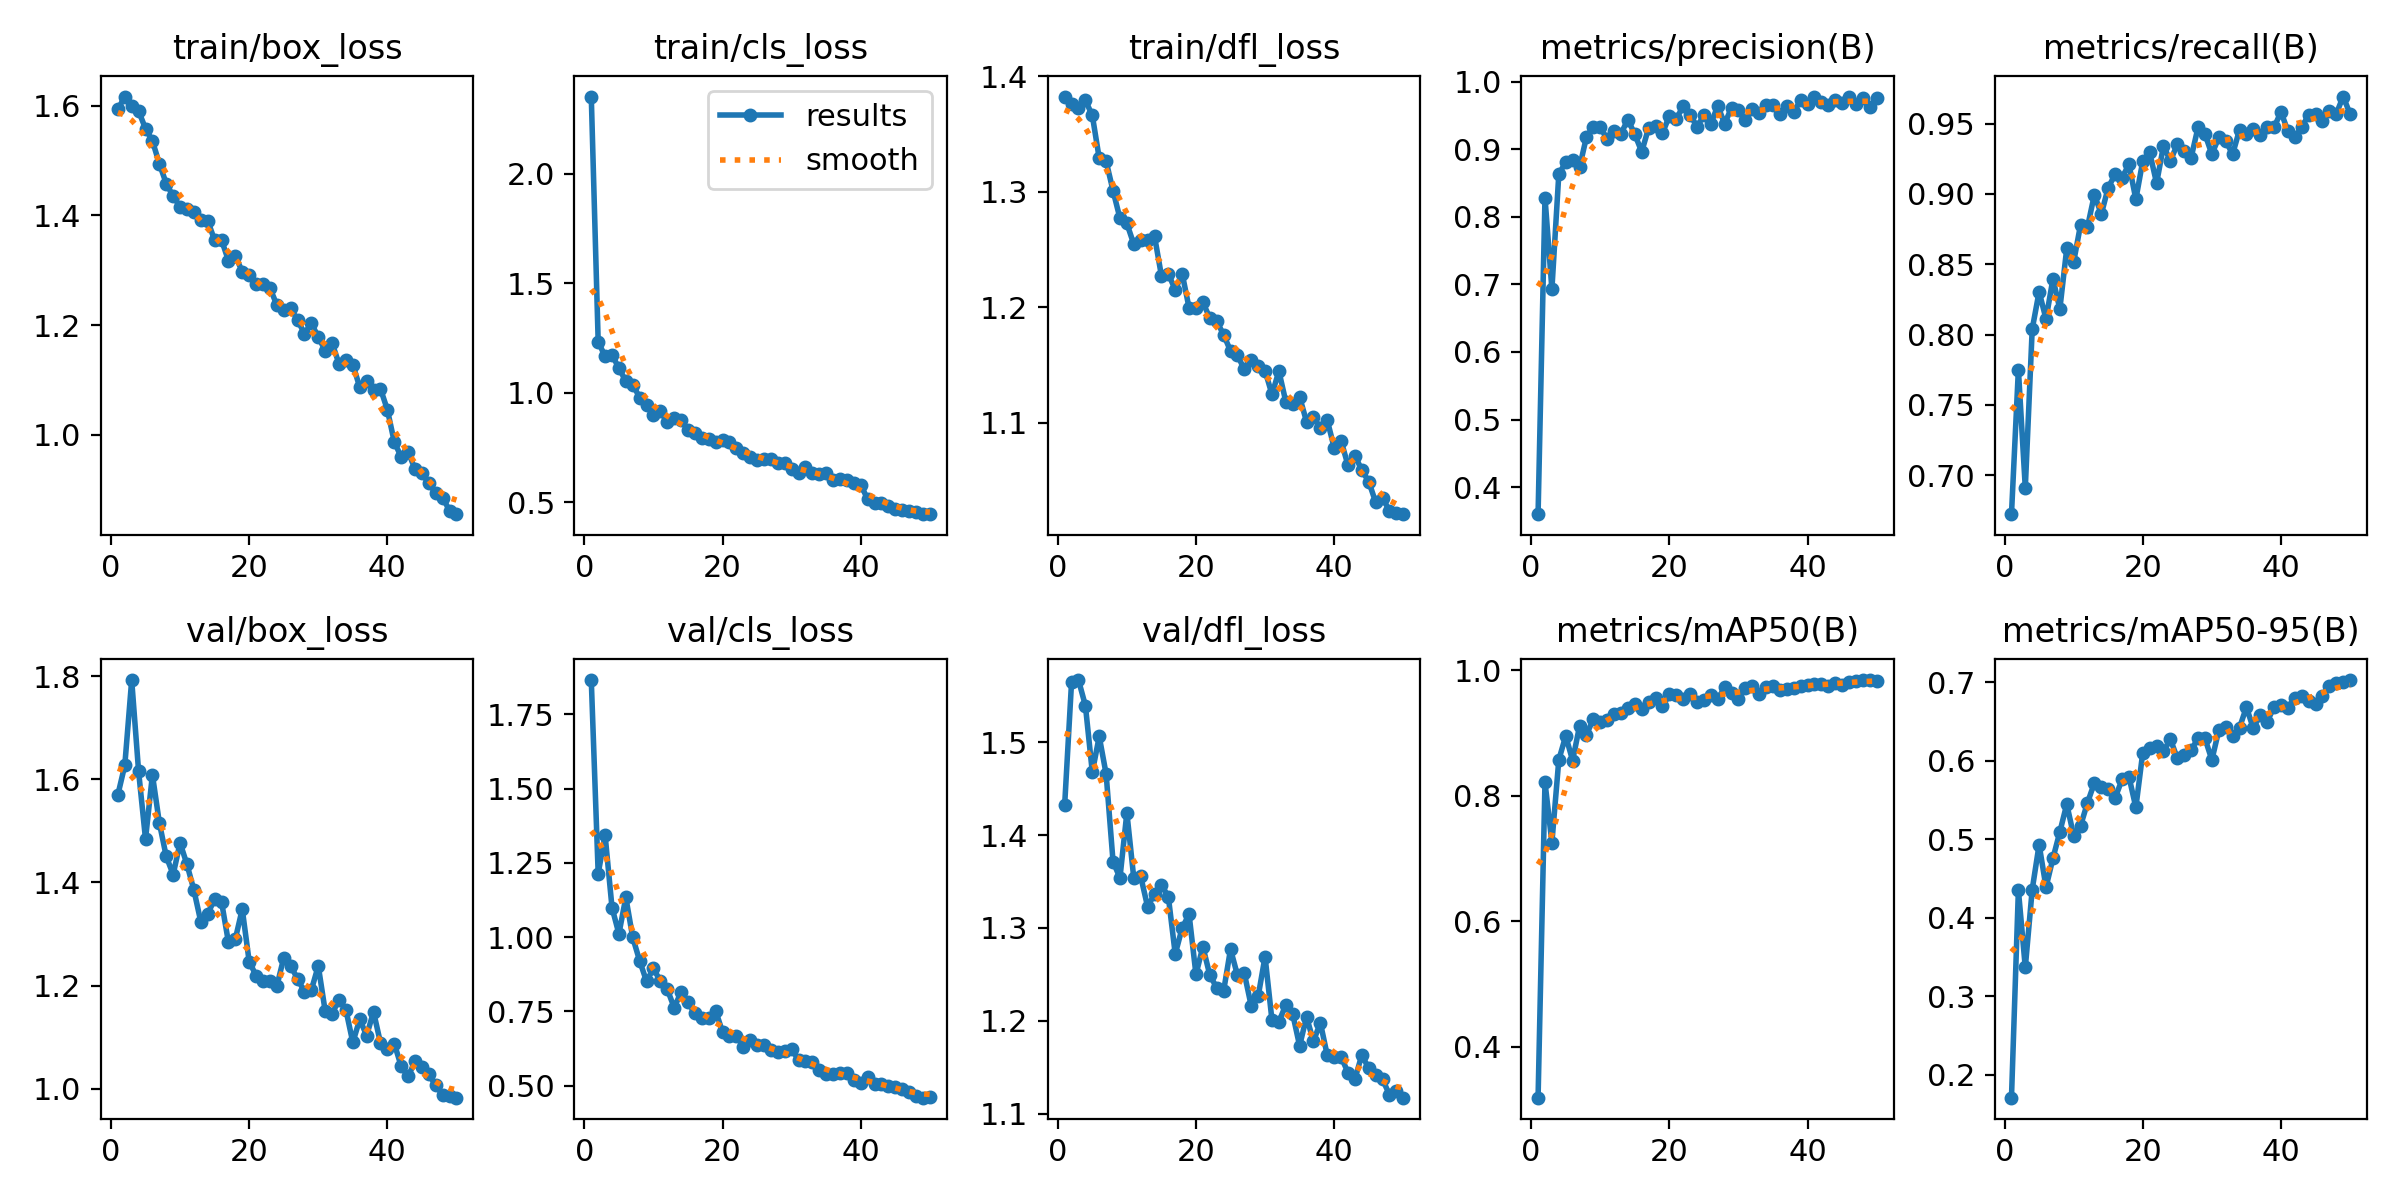

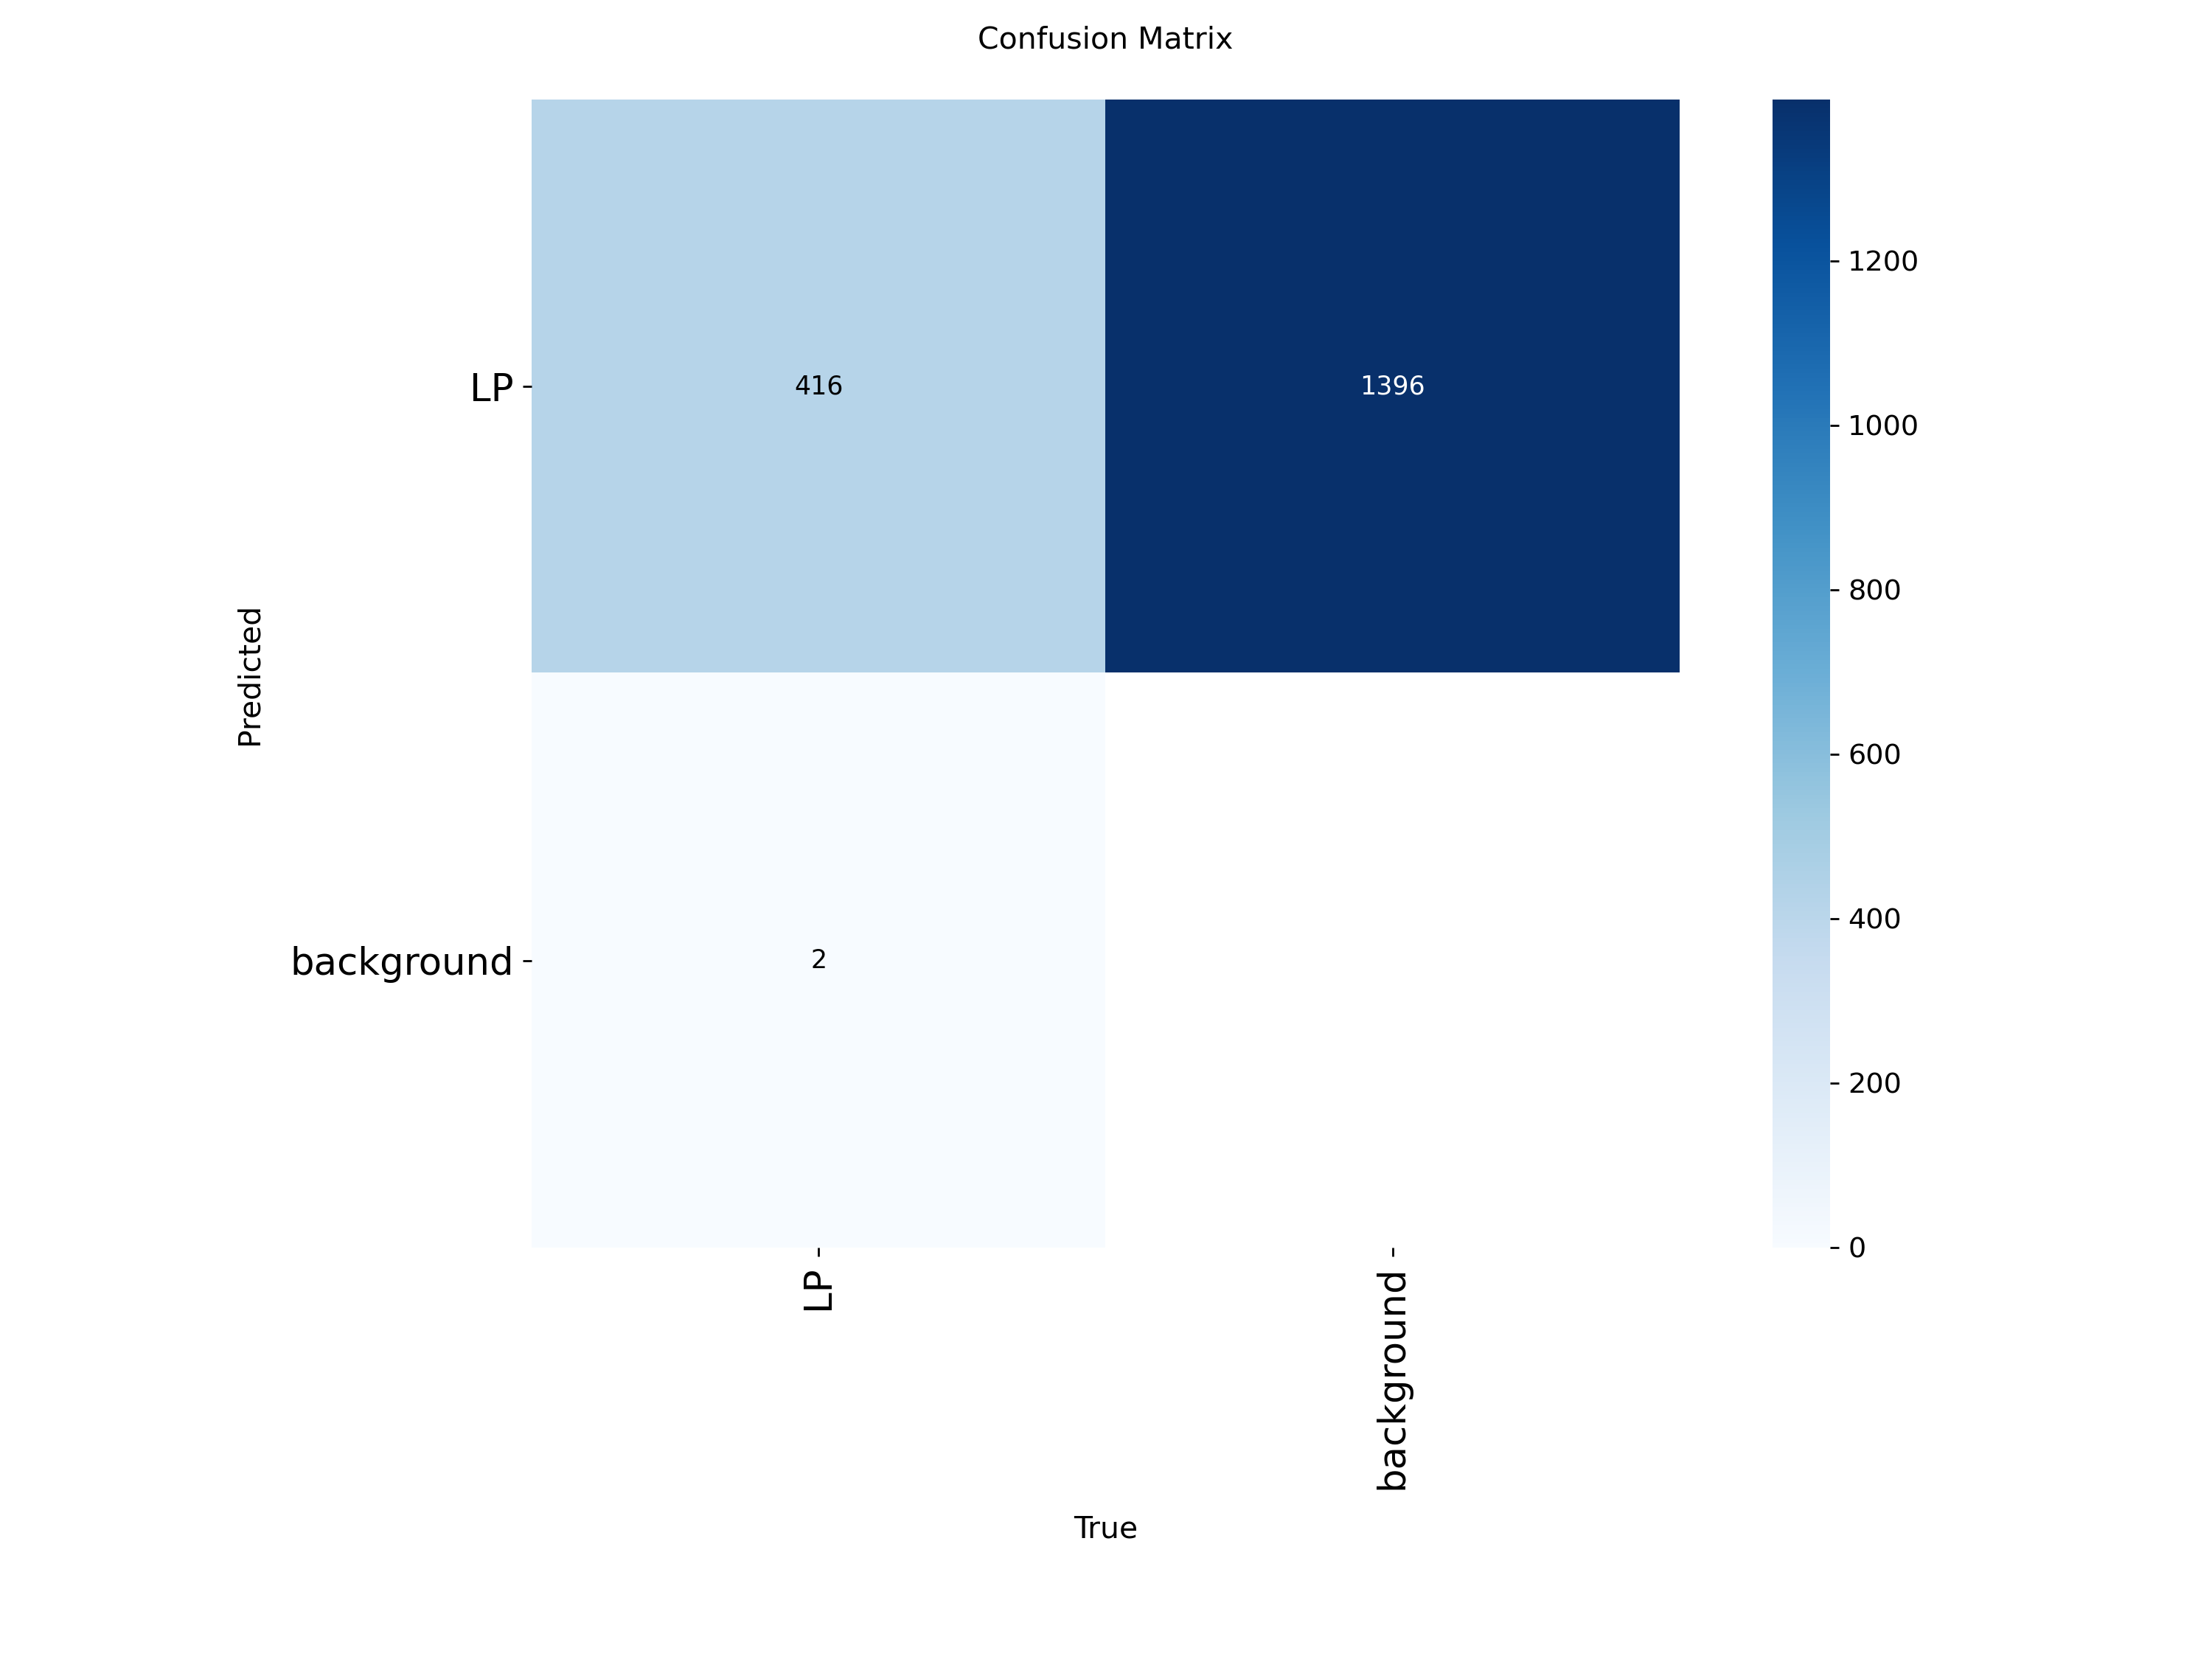

In [11]:
display(Image("runs/detect/plaque/results.png", width=900))
display(Image("runs/detect/plaque/confusion_matrix.png", width=500))

In [12]:
from google.colab import files
files.download("runs/detect/plaque/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>